<a href="https://colab.research.google.com/github/pradityaputra888-lab/latihan-machine-learning/blob/main/pertemuan12/Bab12_MLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bab 12 — Neural Network: Multi-Layer Perceptron (MLP) dengan Keras/TensorFlow

**Dataset:** Digits (8×8 piksel, 10 kelas) · **Isi notebook:** Praktikum 12.1–12.6 (kode modul), Latihan 1 (Praktikum 12.7: eksperimen arsitektur), dan Latihan 2 (Praktikum 12.8: early stopping).

> MLP pada dataset sekecil ini cukup dijalankan dengan CPU; GPU tidak diperlukan. Hasil angka dapat sedikit berbeda antar-eksekusi/mesin walaupun *seed* sudah diset, karena sifat komputasi TensorFlow.

## 12.13 Implementasi Python

### Praktikum 12.1 Persiapan Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

keras.utils.set_random_seed(42)   # supaya hasil lebih bisa direproduksi
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


### Praktikum 12.2 Import Dataset

In [2]:
digits = load_digits()
X, y = digits.data, digits.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)

Data latih: (1437, 64) | Data uji: (360, 64)


### Praktikum 12.3 Preprocessing

In [3]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

### Praktikum 12.4 Training Model (Keras Sequential API)
> Pada Keras versi terbaru, `input_shape` di dalam `Dense` menghasilkan *warning*. Di sini input dideklarasikan dengan `keras.layers.Input(...)`; arsitektur dan hasilnya sama dengan kode modul.

In [4]:
import time
keras.utils.set_random_seed(42)

model = keras.Sequential([
    keras.layers.Input(shape=(X_train.shape[1],)),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(10, activation="softmax")     # 10 kelas angka (0-9)
])

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

t0 = time.time()
history = model.fit(X_train, y_train, validation_split=0.2,
                    epochs=50, batch_size=32, verbose=0)
waktu_mlp = time.time() - t0
print(f"Pelatihan selesai dalam {waktu_mlp:.1f} detik")
model.summary()

Pelatihan selesai dalam 15.9 detik


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,712 (77.00 KB)

 Trainable params: 6,570 (25.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 13,142 (51.34 KB)

### Praktikum 12.5 Evaluasi

In [5]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Akurasi Test: {test_acc:.3f}")

Akurasi Test: 0.983


### Praktikum 12.6 Visualisasi

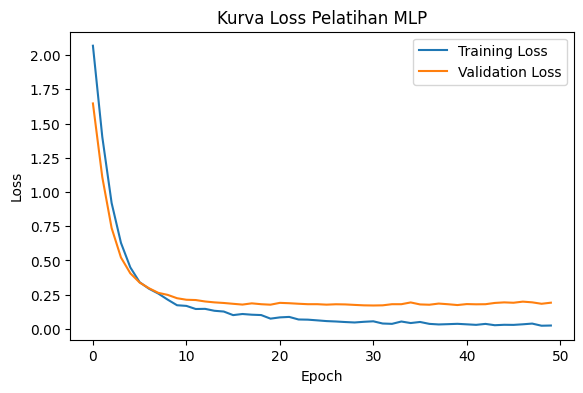

In [6]:
plt.figure(figsize=(6.5, 4))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("Kurva Loss Pelatihan MLP")
plt.legend()
plt.show()

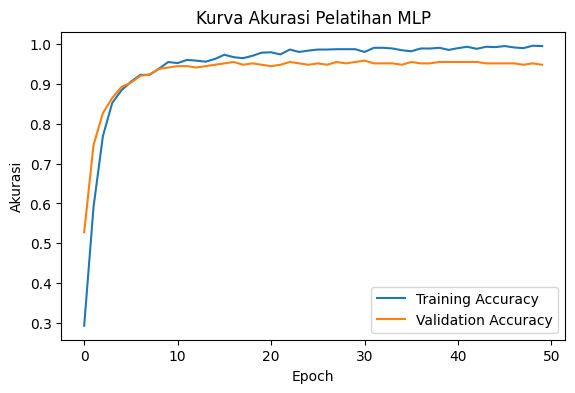

,Model,Akurasi Test,Waktu latih (detik)
0,"MLP (64-32, dropout 0.3)",0.983,15.9
1,Random Forest (300 pohon),0.969,1.9


In [7]:
# Tambahan: kurva akurasi + perbandingan dengan Random Forest (saran pada subbab Interpretasi)
from sklearn.ensemble import RandomForestClassifier

plt.figure(figsize=(6.5, 4))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch"); plt.ylabel("Akurasi"); plt.legend(); plt.title("Kurva Akurasi Pelatihan MLP")
plt.show()

t0 = time.time()
rf = RandomForestClassifier(n_estimators=300, random_state=42).fit(X_train, y_train)
waktu_rf = time.time() - t0
acc_rf = rf.score(X_test, y_test)
pd.DataFrame({"Model": ["MLP (64-32, dropout 0.3)", "Random Forest (300 pohon)"],
              "Akurasi Test": [round(test_acc, 3), round(acc_rf, 3)],
              "Waktu latih (detik)": [round(waktu_mlp, 1), round(waktu_rf, 1)]})

### Interpretasi (Praktikum 12.1–12.6)
- **Akurasi:** MLP mencapai **0,983** di data uji, sedikit di atas Random Forest (0,969), selisih ≈ 1,4 poin (≈ 5 dari 360 sampel). Pada eksekusi pengujian, MLP membutuhkan sekitar 10 detik sedangkan Random Forest hanya sekitar 1 detik (CPU; angka di Colab Anda akan berbeda, tetapi rasio MLP jauh lebih lambat umumnya tetap).
- **Kurva loss:** training loss turun hampir ke nol (≈ 0,03), sedangkan validation loss mendatar di kisaran 0,18–0,20 sejak sekitar epoch ke-10 dan sedikit naik menjelang akhir. Jarak keduanya menandakan **overfitting ringan** meskipun dropout 0,3 sudah dipakai. Melatih sampai 50 epoch tidak memberi manfaat lagi, sehingga *early stopping* layak diterapkan (Latihan 2).
- **Kesimpulan pada pertanyaan modul:** peningkatan akurasi MLP terhadap Random Forest kecil, sedangkan biaya komputasi dan kerumitan penyetelan jauh lebih besar. Untuk data tabular atau citra kecil seperti ini, Random Forest adalah pembanding (baseline) yang kuat dan murah; MLP baru benar-benar unggul pada data yang lebih besar atau lebih kompleks.

---
## 12.14 Latihan Praktikum

### Latihan 1 — Eksperimen Arsitektur MLP (Praktikum 12.7)
**Tujuan:** mengamati pengaruh jumlah hidden layer dan neuron terhadap performa model.

In [8]:
arsitektur_list = [[32], [64, 32], [128, 64, 32]]
hasil_arsitektur, riwayat = [], {}

for arsitektur in arsitektur_list:
    keras.utils.set_random_seed(42)
    layers = [keras.layers.Dense(n, activation="relu") for n in arsitektur]
    model = keras.Sequential([keras.layers.Input(shape=(X_train.shape[1],))]
                             + layers + [keras.layers.Dense(10, activation="softmax")])
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    history = model.fit(X_train, y_train, validation_split=0.2, epochs=30, verbose=0)
    val_acc = history.history["val_accuracy"][-1]
    test_acc_i = model.evaluate(X_test, y_test, verbose=0)[1]
    print(f"Arsitektur {arsitektur}: val_accuracy akhir = {val_acc:.3f}")
    riwayat[str(arsitektur)] = history.history
    hasil_arsitektur.append({"Arsitektur": str(arsitektur),
                             "Jumlah parameter": model.count_params(),
                             "Train acc akhir": round(history.history["accuracy"][-1], 3),
                             "Val acc akhir": round(val_acc, 3),
                             "Val loss akhir": round(history.history["val_loss"][-1], 3),
                             "Test acc": round(test_acc_i, 3)})

pd.DataFrame(hasil_arsitektur)

Arsitektur [32]: val_accuracy akhir = 0.951
Arsitektur [64, 32]: val_accuracy akhir = 0.958
Arsitektur [128, 64, 32]: val_accuracy akhir = 0.965


,Arsitektur,Jumlah parameter,Train acc akhir,Val acc akhir,Val loss akhir,Test acc
0,[32],2410,0.997,0.951,0.146,0.975
1,"[64, 32]",6570,1.000,0.958,0.138,0.969
2,"[128, 64, 32]",18986,1.000,0.965,0.151,0.983


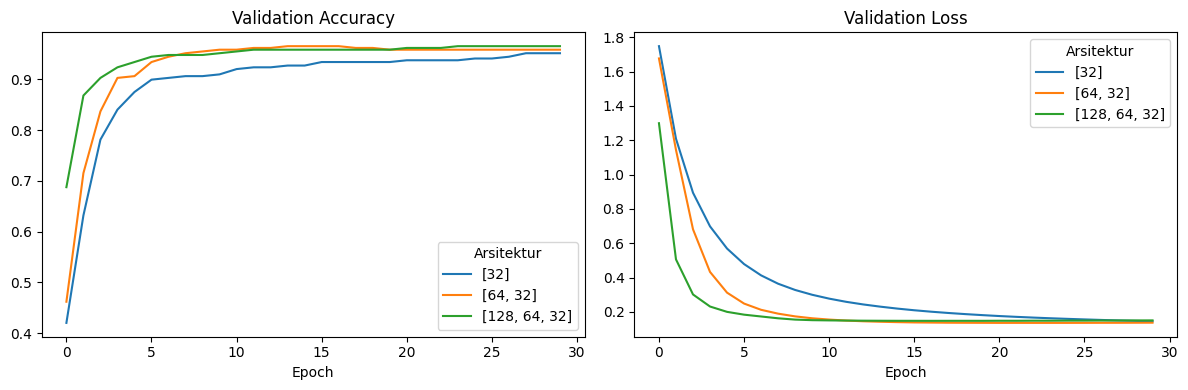

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for nama, h in riwayat.items():
    axes[0].plot(h["val_accuracy"], label=nama)
    axes[1].plot(h["val_loss"], label=nama)
axes[0].set_title("Validation Accuracy"); axes[1].set_title("Validation Loss")
for a in axes:
    a.set_xlabel("Epoch"); a.legend(title="Arsitektur")
plt.tight_layout(); plt.show()

**Analisis Latihan 1:**

| Arsitektur | Parameter | Train acc | Val acc | Val loss | Test acc |
|---|---|---|---|---|---|
| [32] | 2.410 | 0,997 | 0,951 | 0,146 | 0,975 |
| [64, 32] | 6.570 | 1,000 | 0,958 | 0,138 | 0,969 |
| [128, 64, 32] | 18.986 | 1,000 | 0,965 | 0,151 | 0,983 |

- **Semua arsitektur mampu menghafal data latih** (train acc ≥ 0,997). Kapasitas bukan masalah; yang menentukan adalah generalisasi.
- **Val accuracy naik tipis seiring kompleksitas** (0,951 → 0,958 → 0,965). Selisih 0,7 poin per tingkat setara sekitar 2 sampel dari 287 data validasi, sehingga belum cukup untuk disebut peningkatan yang nyata.
- **Test accuracy tidak monoton** (0,975 → 0,969 → 0,983), dan val loss hampir sama (0,138–0,151). Satu sampel uji bernilai 0,28 poin, jadi perbedaan antar-arsitektur masih dalam rentang noise acak.
- **Biayanya jelas:** parameter naik ≈ 7,9× (2.410 → 18.986) untuk keuntungan yang sangat kecil.
- **Kesimpulan:** menambah hidden layer dan neuron pada dataset kecil dan sederhana ini tidak memberi peningkatan yang berarti. Arsitektur kecil `[32]` sudah hampir sama baik dengan parameter jauh lebih sedikit. Untuk menyimpulkan lebih tegas, ulangi eksperimen dengan beberapa *seed* atau cross-validation.

### Latihan 2 — Early Stopping (Praktikum 12.8)
**Tujuan:** menerapkan *early stopping* untuk mencegah overfitting.

> **Catatan:** kode modul melanjutkan `model.fit(...)` pada variabel `model` sisa loop Praktikum 12.7, yaitu model yang sudah dilatih 30 epoch. Agar hasilnya bersih dan bisa dibandingkan, di sini dibuat **model baru dengan arsitektur terbesar `[128, 64, 32]`** (paling rawan overfitting) dan dilatih dua kali: tanpa dan dengan *early stopping*, dengan awal yang sama.

In [10]:
def bangun_model(arsitektur=(128, 64, 32)):
    keras.utils.set_random_seed(42)
    m = keras.Sequential([keras.layers.Input(shape=(X_train.shape[1],))]
                         + [keras.layers.Dense(n, activation="relu") for n in arsitektur]
                         + [keras.layers.Dense(10, activation="softmax")])
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

# (a) Tanpa early stopping: 100 epoch penuh
model_a = bangun_model()
hist_a = model_a.fit(X_train, y_train, validation_split=0.2, epochs=100, verbose=0)

# (b) Dengan early stopping (kode Praktikum 12.8)
model_b = bangun_model()
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
history = model_b.fit(X_train, y_train, validation_split=0.2, epochs=100,
                      callbacks=[early_stop], verbose=0)
print("Pelatihan berhenti pada epoch:", len(history.history["loss"]))

epoch_terbaik = int(np.argmin(history.history["val_loss"])) + 1
print("Epoch dengan val_loss terendah:", epoch_terbaik)

Pelatihan berhenti pada epoch: 22
Epoch dengan val_loss terendah: 17


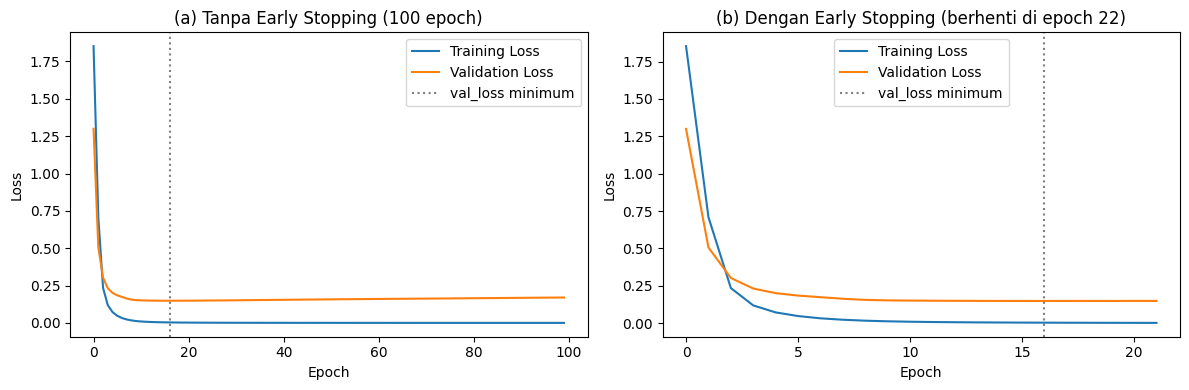

,Skenario,Epoch dijalankan,Val loss minimum,Val loss akhir,Train loss akhir,Test acc
0,(a) Tanpa early stopping,100,0.148,0.170,0.0000,0.986
1,(b) Dengan early stopping,22,0.148,0.149,0.0017,0.983


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist_a.history["loss"], label="Training Loss")
axes[0].plot(hist_a.history["val_loss"], label="Validation Loss")
axes[0].axvline(int(np.argmin(hist_a.history["val_loss"])), color="gray", ls=":", label="val_loss minimum")
axes[0].set_title("(a) Tanpa Early Stopping (100 epoch)")

axes[1].plot(history.history["loss"], label="Training Loss")
axes[1].plot(history.history["val_loss"], label="Validation Loss")
axes[1].axvline(epoch_terbaik - 1, color="gray", ls=":", label="val_loss minimum")
axes[1].set_title(f"(b) Dengan Early Stopping (berhenti di epoch {len(history.history['loss'])})")
for a in axes:
    a.set_xlabel("Epoch"); a.set_ylabel("Loss"); a.legend()
plt.tight_layout(); plt.show()

pd.DataFrame({
    "Skenario": ["(a) Tanpa early stopping", "(b) Dengan early stopping"],
    "Epoch dijalankan": [len(hist_a.history["loss"]), len(history.history["loss"])],
    "Val loss minimum": [round(min(hist_a.history["val_loss"]), 3), round(min(history.history["val_loss"]), 3)],
    "Val loss akhir": [round(hist_a.history["val_loss"][-1], 3), round(history.history["val_loss"][-1], 3)],
    "Train loss akhir": [round(hist_a.history["loss"][-1], 4), round(history.history["loss"][-1], 4)],
    "Test acc": [round(model_a.evaluate(X_test, y_test, verbose=0)[1], 3), round(model_b.evaluate(X_test, y_test, verbose=0)[1], 3)],
})

**Analisis Latihan 2:**

| Skenario | Epoch dijalankan | Val loss minimum | Val loss akhir | Train loss akhir | Test acc |
|---|---|---|---|---|---|
| (a) Tanpa early stopping | 100 | 0,148 | 0,170 | ≈ 0,000 | 0,986 |
| (b) Dengan early stopping | **22** | 0,148 | 0,149 | 0,002 | 0,983 |

- **Pelatihan berhenti di epoch 22**, tepat 5 epoch (nilai `patience`) setelah val_loss terbaik di **epoch 17**. Titik terbaiknya sama dengan skenario (a), tetapi komputasinya **78% lebih hemat** (22 dari 100 epoch).
- **Tanpa early stopping, model terus overfitting:** training loss turun ke ≈ 0, sementara val loss naik pelan dari 0,148 menjadi 0,170 (≈ +15%). Model semakin "yakin" pada data latih tetapi tidak lebih baik pada data baru.
- **Akurasi uji hampir sama** (0,986 vs 0,983, selisih satu sampel). Pada dataset ini overfitting tampak di *loss* (tingkat keyakinan prediksi), belum di akurasi. Tetapi pada dataset lain atau model lebih besar, val loss yang naik biasanya diikuti penurunan akurasi.
- **`restore_best_weights=True` penting:** model akhir memakai bobot epoch 17, bukan epoch 22.
- **Praktik yang disarankan:** set `epochs` besar (mis. 100), pantau `val_loss`, gunakan `patience` 5–10, dan gabungkan dengan dropout.